# Théorie :

**Problème d'un MLP sur une image** : il faut l'applatir en vecteur, on perds la structure spatiale et necessite bcp de poids + instable aux transformation géométrique (translation, symétrie ...).  
On a donc partir sur une structure différentes : **Les CNNs**  
On va utiliser un ensemble de filtres (somme pondérées sur l'imagette ...). Le poids de chaque filtre est commun à toute l'image, chaque filtre devient un détecteur de motif (ligne droite, courbe droite ...)  

Un CNN contient plusieurs couches :  
1. **Convolution** : Produit une feature map par filtre. (Notions à maitriser : noyau, stride, padding, nombre de canaux d'entrée et de sortie.)
2. **Activation (ReLu)** : comme dans le MLP
3. **Pooling** (max pooling) : réduit la taille de la carte et donne une tolérance aux petits décalages.
4. **Aplatissement puis couche dense** : à la fin, on retombe sur un MLP qui classe à partir des motifs détectés (Cette fois, on ne fera pas le MLP entier mais simplifié avec la backprog intégrée à PyTorch)
5. **Sortie** : softmax avec 2 classes (carré/cercle), ou 1 neurone sigmoïde. Loss = cross-entropy

**Apprentissage** : même principe que MLP (boucle {forward, loss, backprog, maj des w} jusqu'à un stop). La nouveauté est que le gradient d'une convolution est lui-même une convolution (avec le filtre retourné), et que celui du max pooling n'est transmis qu'à la position du maximum.

![alt text](data/TP-CNN-architecture-1.jpg)

## Couches cachés du CNN disponibles
Ce sont les couches qui pourront par la suite être assemblées pour construire selon nos besoin notre réseau

In [274]:
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_openml
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm


### *1. Notions liés à la convolution*
#### *Vocabulaire*
**Noyau :**   
- Petite matrice de poids de taille (k.k) apprise pendant l'entrainement. Elle est la même pour toute l'image.

**Fenêtre :**  
- imagette issus de la matrice qu'on fait glisser sur l'image (3x3 par exemple).
- C'est la fenêtre sur laquelle on applique la transformation : multiplication terme à terme `fenetre * noyau`, puis on somme pour obtenir 1 valeur.

**Stride (pas) :**  
- Combien de case le noyau se déplace

**Padding :**  
- Présence ou non de bordure rajouté autour de l'entrée
  - padding = 'valid' : aucun rajout. Sortie de taille `-(k-1)` sur chaque axe
  - padding = 'same' : on rajoute des valeurs sur le contour de l'entrée (anneau taille 1), qui fait que la sorti est de taille identique à l'entrée : `torch.nn.functional.pad` sur l'entrée (Identique seulement si noyau impair et stride=1)

**Canaux :**  
- Nombre c de matrices (x,y) utilisés pour representer l'image de taille (c,x,y)

#### *Taille impliqué dans la convolution :*
1. **Entrée**
- `C_in` : nombre de canaux d'entrée
- `H` : hauteur de l'image (donc nbr de lignes)
- `W` : largeur ... (nbr de colonnes)
- `N` : nombre d'image du batch
  - Forme de l'entrée : `(N, C_in, H, W)`   

2. **Hyperparamètres de la couche**
- `C_out` : nombre de filtres, donc nbr canaux de sortie
- `k` : taille du noyau (k*k, souvent 3)
- `s` : stride, le pas de déplacement
- `P`: padding, nombre de cases ajoutées sur les bords (avec `'valid'`, P = 0)  

3. **Intermédiaire : ce que la couche contient**
- Noyau : matrice `k*k` pour un canal
  - initialisé aléatoirement, avec des valeurs raisonnable : `torch.randn(C_out, C_in, k, k) / √(C_in·k²)` (eviter explosion ou vanishing) 
- Filtre : `C_in` noyaux, de forme `(C_in, k, k)`
  - Tous les filtres ensemble : forme (`(C_out, C_in, k, k)`)
- Biais : `C_out` valeurs, une par filtre
  - initialisation nulle : `torch.zeros(C_out)`
- Nombre de paramètres appris : `C_out * C_in * k * k + C_out`  

1. **Sortie**
- De forme `(N, C_out, H_out, W_out)`
- $H_{out} = floor[(H - k + 2P)/s] +1$
- $W_{out} = floor[(W - k + 2P)/s] +1$
  - avec `'valid'` et un stride de 1, on retrouve `H-k+1` et `W-k+1`, soit `H-2` et `W-2` pour k = 3

#### *Resumé :*
**Entrée** **$\to$** Un batch de forme `(N, C_in, H, W)`. Si `C_in` ne correspond pas, on lève une erreur.

**Noyaux** **$\to$** un seul tenseur `(C_out, C_in, k, k)` (un filtre par canal de sortie, initialisation Xavier) et un biais `(C_out)` (initialisé à 0)

**Padding** **$\to$** `'valid'` donne `P=0`, `'same'` donne `P = (k-1)//2`, et un entier est utilisé tel quel. On pad uniquement sur `H` et `W` (pas les canaux ou N)  

**Fenêtre** **$\to$** `x.unfold(2, k, stride).unfold(3, k, stride)` extrait toutes les fenêtres d'un coup, sans boucle. Chaque `unfold` ajoute une dimension de taille `k` à la fin: on obtient `(N, C_in, H_out, W_out, k, k)`

**Convolution** **$\to$** `torch.einsum("nchwab,ocab->nohw", fenetre, noyau)`avec `n`: image, `c`: canal d'entrée, `h`,`w`: position de la fenêtre, `a`,`b`: position dans le noyau, `o`: filtre de sortie. Les indices absents de la sortie (`a,b,c`) sont sommés : c'est la somme pondérée terme à terme. On ajoute ensuite le biais, remis en forme `(1, C_out, 1, 1)`

**Sortie** **$\to$** `(N, C_out, H_out, W_out)`: Chaque canal de sortie correspond à un filtre. Tout le batch est calculé en parallèle sur le GPU.

In [29]:
class Conv:
    def __init__(self, C_in=1, C_out=6, kernel=3, stride=1, padding="valid"):
        '''
        C_in : nbr de canaux d'entrée - 3 pour RGB ...
        C_out : nombre de filtre et donc nombre de canaux en sortie de convolution
        kernel : taille k du noyau (k x k)
        stride : pas de déplacement de la fenêtre d'application du noyau
        padding : 'valid' (P=0), 'same' (P=(k-1)//2) ou entier >= 0
        '''
        if kernel <= 0 or stride <= 0 or C_in <= 0 or C_out <= 0:
            raise ValueError(f"kernel {kernel}, stride {stride}, C_in {C_in} et C_out {C_out} doivent être positifs")
        if padding not in ['valid', 'same'] and (not isinstance(padding, int) or padding < 0):
            raise ValueError(f"padding {padding} doit être 'valid', 'same' ou entier >= 0")
        
        self.C_in, self.C_out = C_in, C_out
        self.k, self.stride = kernel, stride
        self.padding = padding

        

        # Traduction du padding str -> int
        pad_dict = {'valid': 0, 'same': (self.k - 1)//2}
        if padding in pad_dict:
            self.P = pad_dict[padding]
        elif isinstance(padding, int):
            self.P = padding
        else:
            raise KeyError("Definir padding pour 'valid', 'same' ou entier")

        # Initialisation des poids (C_out, C_in, k, k)
        self.noyau = (torch.randn(C_out, C_in, kernel, kernel, device=device) / (C_in * kernel**2) ** 0.5).requires_grad_()
        self.biais = torch.zeros(C_out, device=device, requires_grad = True)

    def parameters(self):
        return [self.noyau, self.biais]

    def forward(self, x):                   # x : (N, C_in, H, W)
        if x.shape[1] != self.C_in:
            raise ValueError(f"Conv attend {self.C_in} canaux en entrée, recu {x.shape[1]}")
        if self.P > 0:
            x = torch.nn.functional.pad(x, (self.P, self.P, self.P, self.P))
        H_out = (x.shape[-2] - self.k) // self.stride + 1
        W_out = (x.shape[-1] - self.k) // self.stride + 1 
        if H_out <= 0 or W_out <= 0:
            raise ValueError(f"Image trop petite ({x.shape[-2]}x{x.shape[-1]}) pour un noyau {self.k}x{self.k}")

        fenetre = x.unfold(2, self.k, self.stride).unfold(3,self.k,self.stride) # (N, C_in, H_out, W_out, k, k)
        # avec self.noyau de shape (C_out, C_in, k, k) et self.biais de shape (C_out,)
        return torch.einsum("nchwab,ocab->nohw", fenetre, self.noyau) + self.biais[None,:,None,None] # (N, C_out, H_out, W_out)

### *2. Notions liées au pooling*

Pas de padding possible ici, on a forcement une réduction de taille (plus ou moins importante en fonction de `k` et `stride`)  
On part de **`(N, C, H, W)`** pour finir en **`(N, C, H_out, W_out)`**, avec :  
- $$\mathbf{H_{out} = \left\lfloor \frac{H - k}{stride} \right\rfloor + 1 \qquad | \qquad W_{out} = \left\lfloor \frac{W - k}{stride} \right\rfloor + 1}$$
- On rajoute 2 dimension de taille k, c'est notre fenêtre
- Puis on regarde le max sur cette fenêtre **`torch.amax(x, dim=(-2,-1))`**

Cette écriture plutôt qu'une boucle permet aussi de faire les calculs en parallèles, et donc d'aller beaucoup plus vite (combiner avec toutes les données chargées sur le GPU)

In [30]:
class Pool:
    def __init__(self, kernel=2, stride=2, type='max'):
        '''
        kernel : taille k du noyau (k x k)
        stride : pas de déplacement de la fenêtre d'application du noyau
        type : type de pooling ('max' ou 'mean')
        '''
        if kernel <= 0 or stride <= 0:
            raise ValueError("kernel et stride doivent être positifs")
        if type not in ('max', 'mean'):
            raise ValueError("pool doit être du type 'max' ou 'mean'")
        
        self.k = kernel
        self.stride = stride
        self.type = type

    def parameters(self):
        return []

    def forward(self, x):   # x : (N, C, H, W), pas de padding possible
        H_out = (x.shape[-2] - self.k) // self.stride + 1
        W_out = (x.shape[-1] - self.k) // self.stride + 1
        if H_out <= 0 or W_out <= 0:
            raise ValueError(f"Image trop petite ({x.shape[-2]}x{x.shape[-1]}) pour un noyau {self.k}x{self.k}")
        fenetre = x.unfold(2, self.k, self.stride).unfold(3,self.k,self.stride) # (N, C, H_out, W_out, k, k)
        if self.type == 'max':
            return torch.amax(fenetre, dim=(-2,-1))  # (N, C, H_out, W_out)
        elif self.type == 'mean':
            return torch.mean(fenetre, dim=(-2,-1))  # (N, C, H_out, W_out)
        else:
            raise KeyError(f"problème de définition de self.type : {self.type}")

### Fonction d'activation
Appliquer après la convolution. Permet d'apporter une non linéarité  
On pourrait en mettre d'autres (tanh ...)

In [31]:
class ReLu:
    def parameters(self):
        return []

    def forward(self, x):
        return torch.relu(x) # max(0,x)

### Flatten
Appliquer avant la couche dense : Permet d'avoir le bon format pour rentrer dans un MLP

In [32]:
class Flatten:
    def parameters(self):
        return []

    def forward(self, x):
        return x.flatten(1)     # (N, C, H, W) -> (N, C*H*W)

### DropOut
Permet de faire sauter des neuronnes dans le dense, pour le forcer a passer par tout les chemins, et donc eviter le sur-apprentissage ou des neuronnes morts

In [33]:
class DropOut:
    '''
    A placer avant un flatten, pour "tuer des neuronnes" aléatoirement
    '''
    def __init__(self, p=0.5):
        if 0 <= p < 1:
            self.p = p
        else:
            raise ValueError(f"p doit etre entre [0,1[, {p} invalide.")  
        self.training = True

    def parameters(self):
        return []
    
    def forward(self, x):
        if not self.training:
            return x
        else:
            masque = (torch.rand_like(x, device=device) >= self.p).float()
            return x * masque / (1 - self.p)

### Dense
MLP qui apprend des filtres en entrée (representation "apprise" de l'image initiale) pour prédire la classe

In [34]:
class Dense:
    def __init__(self, n_out):
        self.n_in = None    # Connu seulement après le 1er passage
        self.n_out = n_out
        self.W = None
        self.b = None

    def parameters(self):
        if self.W is None:
            raise RuntimeError("Dense enconre non initialisé : faire tourner le modèle (premier passage)")
        return [self.W, self.b]

    def forward(self, x):
        if x.ndim != 2:
            raise ValueError(f"Dense attend une entrée (N, n_in), recu {x.shape} : oubli de Flatten ?")
        if self.W is None:
            self.n_in = x.shape[1]
            self.W = (torch.randn(self.n_in, self.n_out, device=device) / self.n_in ** 0.5).requires_grad_()
            self.b = torch.zeros(self.n_out, device=device, requires_grad=True)
        elif x.shape[1] != self.n_in:
            raise ValueError(f"Dense attend {self.n_in} entrées, recu {x.shape[1]}")
        return x @ self.W + self.b # logits (softmax dans la cross-entropy)

### Fonction de loss
Base de l'optimiseur. Permet de décrire quel prediction et fausse et de la corriger dans la backprog

In [35]:
###TODO###
class loss:
    def __init__(self, loss='cross-entropy'):
        self.loss = loss

    def CE(self):
        pass

###TODO###

## Modèle
Maintenant que toutes les couches/fonctions nécéssaires sont définis, on peut construire notre modèle  
Il consiste en un "chef d'orchestre" lors de l'entrainement :
- Il fait passer le signal couche par couche jusqu'au bout
- calcul de la loss
- Retro-propagation du gradient 
- Puis recommence la boucle jusqu'a ce qu'un critère d'arret stop l'entrainement

Il sert ensuite, avec les poids sauvegardé de l'entrainement, à prédire la classe d'un batch d'image (batch taille 1 possible)

Pour les critères d'arret, ici j'ai choisi de me baser sur :
- Epoch : classique
- La variation de la loss entre epoch: si on ne bouge pas ou augmente pendant `patience` epoch -> stop (calcul fait sur la loss de validation, pas de train: evite le sur-apprentissage)

In [162]:
class Modele:
    def __init__(self, features, classifier, input_shape=(1, 28, 28), EPOCH=100, lr=0.1, batch_size=128, patience=5, eps=1e-4):
        '''
        couches : liste de couches appliquées dans l'ordre
        input_shape : (C, H, W) d'une image, pour le passage à blanc qui fixe la taille des Dense
        '''
        self.features = features
        self.classifier = classifier
        self.couches = np.concatenate((features, classifier))
        self.input_shape = input_shape
        self.EPOCH = EPOCH
        self.lr = lr
        self.batch_size = batch_size
        self.patience = patience
        self.eps = eps

    def parameters(self):
        p = []
        for c in self.couches:
            p.extend(param for param in c.parameters() if param.requires_grad)
            # p.append(c.parameters())
        return p

    def train(self):
        for c in self.couches:
            if hasattr(c, "training"):
                c.training = True

    def eval(self):
        for c in self.couches:
            if hasattr(c, "training"):
                c.training = False

    def forward(self, x):
        for c in self.couches:
            x = c.forward(x)
        return x

    def evaluate(self, x, y):
        self.eval()     # Desactiver toutes les couches de training (DropOut ...)
        total_loss, correct = 0., 0
        with torch.no_grad():
            for i in range(0, len(x), self.batch_size):
                xb, yb = x[i:i+self.batch_size], y[i:i+self.batch_size]
                yhat = self.forward(xb)
                total_loss += -torch.log_softmax(yhat, dim=1)[torch.arange(len(yb), device=yhat.device), yb].sum().item()
                correct += (torch.argmax(yhat, dim=1) == yb).sum().item()
        return total_loss / len(x), correct / len(x) # loss , accuracy
    
    def fit(self, x, y, x_val, y_val):
        self.perf_fit = []
        self.min_loss = float("inf")
        self.best_param = None
        wait = 0
        
        loader = DataLoader(TensorDataset(x,y), batch_size=self.batch_size, shuffle=True, drop_last=True)

        barre_epoch = tqdm(range(self.EPOCH), desc="Epochs")
        for epoch in barre_epoch:
            self.train()    # activer toutes les couches permettant d'encadrer l'entrainement  (DropOut ...)

            batch_loss = []
            batch_accuracy = []

            for xb, yb in tqdm(loader, desc="Batchs", leave=False):
                yhat = self.forward(xb)
                p = self.parameters()

                loss = -torch.log_softmax(yhat,dim=1)[torch.arange(yhat.shape[0], device=yhat.device),yb].mean()

                for param in p:
                    param.grad = None
                
                loss.backward()
                with torch.no_grad():
                    for param in p:
                        param -= self.lr * param.grad   # back propagation du gradient (in place fonctionne dans la boucle)

                batch_loss.append(loss.item())
                batch_accuracy.append((torch.argmax(yhat, dim=1) == yb).float().mean().item())

            val_loss, val_accuracy = self.evaluate(x_val, y_val)
            self.perf_fit.append([np.mean(batch_loss), np.mean(batch_accuracy), val_loss, val_accuracy])
            barre_epoch.set_postfix(loss=f"{np.mean(batch_loss):.4f}", val_loss=f"{val_loss:.4f}", val_acc=f"{val_accuracy:.4f}")

            if val_loss < self.min_loss - self.eps:
                wait = 0
                self.min_loss = val_loss
                self.best_params = [param.detach().clone() for param in self.parameters()]
            else:
                wait += 1
                if wait >= self.patience:
                    tqdm.write(f"Early stop at epoch {epoch + 1}")
                    break

        with torch.no_grad():
            for param, best in zip(self.parameters(), self.best_params):
                param.copy_(best)

        self.eval() # Desactiver toutes les couches de training (DropOut ...): modele pret pour predict pour la suite
        
        print(f"Stop apres {len(self.perf_fit)} epochs : val_loss={self.min_loss:.4f}")

    def predict(self, x):
        self.eval()     # Desactiver toutes les couches de training (DropOut ...)
        with torch.no_grad():
            f = self.forward(x).detach()
        return torch.argmax(f, dim=1)      


### Import des données
Bien tout charger sur le GPU pour avoir l'acceleration.
Test possible avec un sample de 10.000 images ...

In [163]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_mnist, y_mnist = fetch_openml('mnist_784', return_X_y=True, as_frame=False)
X_mnist = X_mnist.reshape(-1, 28, 28) / 255.        # (N, 784) -> (N, 28, 28), valeurs dans [0, 1]
y_mnist = y_mnist.astype(np.int64)

# indices = resample(np.arange(len(X_mnist)),n_samples=10000,replace=False,random_state=42)
# X_mnist = X_mnist[indices]
# y_mnist = y_mnist[indices]

# L'ordre de retour de train_test_split est X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(
    X_mnist, y_mnist, test_size=0.2, random_state=42, stratify=y_mnist
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)

# Tensors pour le modèle : images (N, 1, 28, 28) float32, labels (N,) int64
X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1).to(device)
X_test  = torch.tensor(X_test,  dtype=torch.float32).unsqueeze(1).to(device)
X_val   = torch.tensor(X_val,   dtype=torch.float32).unsqueeze(1).to(device)
y_train = torch.tensor(y_train, dtype=torch.long).to(device)
y_test  = torch.tensor(y_test,  dtype=torch.long).to(device)
y_val   = torch.tensor(y_val,   dtype=torch.long).to(device)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

torch.Size([50400, 1, 28, 28]) torch.Size([50400]) torch.Size([14000, 1, 28, 28]) torch.Size([14000])


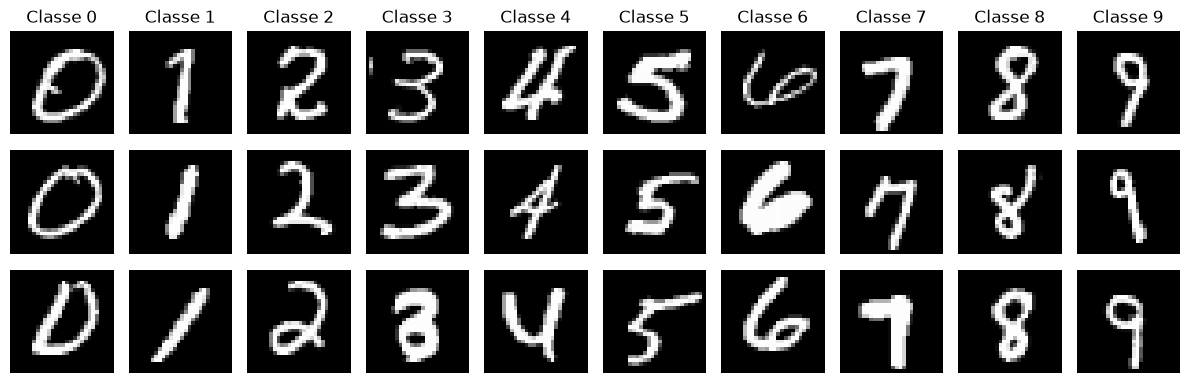

In [164]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4))

x_visu = [X_train[y_train == k][:3].cpu() for k in range(10)]

for classe in range(10):
    for exemple in range(3):
        ax = axes[exemple, classe]
        ax.imshow(x_visu[classe][exemple].squeeze(0), cmap="gray")
        ax.axis("off")
        if exemple == 0:
            ax.set_title(f"Classe {classe}")

plt.tight_layout()
plt.show()

### Construction du modèle
#### 1er modele : "small"
1 couche de chaque, hyperparamètre pas trop spécifiques.  
Environ 40/45s pour tourner, accuracy dans les **98.19 % (± 0.10)** (pas de cv ici)

#### 2nd modèle : "medium"
On essaye quelque chose d'un peu plus complexe, avec 2 layers convolution|activation|maxpool et plus de filtres  
early stop après 26 epoch (35s), accuracy **98/99%**

#### 3ieme modele : "large"
On met une validation croisée pour avoir des résultats qui varient moins entre les relances, et pouvoir percevoir si on a ou pas une amélioration. Donc on refusionne la validation pour pouvoir changer le jeu de validation dans chaque pli.  
On obtient **98.58% +/- 0.14** en 3m10 


In [279]:
X_all = torch.cat((X_train, X_val))
y_all = torch.cat((y_train, y_val))

def creer_modele_small(input_shape=(1, 28, 28), EPOCH=55, lr=0.1, batch_size=512, patience=12, eps=1e-5):
    features = [Conv(C_in=1,C_out=64,kernel=3,stride=1,padding='valid'), ReLu(),
                Conv(C_in=64,C_out=32,kernel=3,stride=1,padding='valid'), ReLu()]
    classifier = [Flatten(), Dense(n_out = 10)]
    return Modele(features, classifier, input_shape=input_shape, EPOCH=EPOCH, lr=lr, batch_size=batch_size, patience=patience, eps=eps)

def creer_modele_medium(input_shape=(1, 28, 28), EPOCH=65, lr=0.3, batch_size=512, patience=12, eps=1e-5):
    features = [Conv(C_in=1, C_out=32, kernel=5, stride=1, padding='valid'), ReLu(), 
                Pool(kernel=2, stride=2, type='max'), DropOut(p=0.2)]
    classifier = [Flatten(), Dense(n_out=128), ReLu(), Dense(n_out = 10)]
    return Modele(features, classifier, input_shape=input_shape, EPOCH=EPOCH, lr=lr, batch_size=batch_size, patience=patience, eps=eps)

def creer_modele_large(input_shape=(1, 28, 28), EPOCH=75, lr=0.1, batch_size=512, patience=12, eps=1e-5):
    features = [Conv(C_in=1, C_out=30, kernel=5, stride=1, padding='valid'), ReLu(), Pool(kernel=2, stride=2, type='max'),
                Conv(C_in=30, C_out=15, kernel=3, stride=1, padding='valid'), ReLu(), Pool(kernel=2, stride=2, type='max'),
                DropOut(p=0.2)]
    classifier = [Flatten(), Dense(n_out=128), ReLu(), 
                  Dense(n_out=50), ReLu(), Dense(n_out=10)]
    return Modele(features, classifier, input_shape=input_shape, EPOCH=EPOCH, lr=lr, batch_size=batch_size, patience=patience, eps=eps)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = {'ms': [], 'mm': [], 'ml': []}
 
for k, (idx_tr, idx_va) in enumerate(skf.split(np.zeros(len(y_all)), y_all.cpu().numpy())):
    idx_tr = torch.tensor(idx_tr, device=device)
    idx_va = torch.tensor(idx_va, device=device)

    torch.manual_seed(42 + k)
    models = {'ms': creer_modele_small(),
              'mm': creer_modele_medium(),
              'ml': creer_modele_large()}

    for name, m in models.items():
        m.fit(X_all[idx_tr], y_all[idx_tr], X_all[idx_va], y_all[idx_va])

        val_loss, val_acc = m.evaluate(X_all[idx_va], y_all[idx_va])
        scores[name].append(val_acc)
        print(f"{name} : Pli {k + 1}/5 : val_loss={val_loss:.4f}, accuracy={val_acc * 100:.2f} %")

print('\n')
print('\n')

for name in models:   
    print(f"{name} : Accuracy moyenne : {np.mean(scores[name]) * 100:.2f} % (± {np.std(scores[name]) * 100:.2f})")


Epochs:   0%|          | 0/55 [00:00<?, ?it/s]

Batchs:   0%|          | 0/87 [00:00<?, ?it/s]

Batchs:   0%|          | 0/87 [00:00<?, ?it/s]

Batchs:   0%|          | 0/87 [00:00<?, ?it/s]

Batchs:   0%|          | 0/87 [00:00<?, ?it/s]

Batchs:   0%|          | 0/87 [00:00<?, ?it/s]

... (763 outputs left out)

Batchs:   0%|          | 0/87 [00:00<?, ?it/s]

Batchs:   0%|          | 0/87 [00:00<?, ?it/s]

Batchs:   0%|          | 0/87 [00:00<?, ?it/s]

Stop apres 75 epochs : val_loss=0.0315
ml : Pli 5/5 : val_loss=0.0315, accuracy=99.09 %




ms : Accuracy moyenne : 98.10 % (± 0.13)
mm : Accuracy moyenne : 98.89 % (± 0.12)
ml : Accuracy moyenne : 99.09 % (± 0.07)


#### Modele 4 : Recherche Hyper-paramètres optimaux pour notre problème  
| Couche | Rôle | Effet sur l'apprentissage | Placement |
|---|---|---|---|
| **Conv** | Détecte des motifs locaux avec des poids partagés | Plus de filtres = plus de motifs, mais plus de paramètres. Un `k` plus grand = champ réceptif plus large, mais plus coûteux | Au début : traits simples (bords). Plus profond : formes complexes |
| **ReLU** | Non-linéarité | Sans elle, deux Conv empilées équivalent à une seule opération linéaire : la profondeur ne sert à rien. Risque de neurones « morts » si le `lr` est trop fort | Après chaque Conv ou Dense cachée, **jamais** sur les logits de sortie |
| **MaxPool** | Réduit la taille, tolère les petits décalages | Aucun paramètre. Réduit le coût et la taille du Dense. Perd la position précise : trop de pooling tôt fait chuter l'accuracy | Après un bloc Conv + ReLU. En général 1 pooling pour 1 à 2 Conv |
| **Flatten** | Passe du 2D au vecteur | Aucun apprentissage. Il fixe `n_in` du Dense, donc la taille du Dense en dépend directement | Juste avant les Dense |
| **Dense** | Combine toutes les features globalement | Beaucoup de paramètres, donc source principale de sur-apprentissage. Une Dense cachée ajoute de la capacité en fin de réseau | Fin du réseau. La dernière donne les logits (sans ReLU) |


**Règles pratiques :**  
- **Résolution et canaux** : à chaque pooling qui divise la taille par 2, on double les filtres (ton 16 → 32). Le réseau abandonne la précision spatiale pour des motifs plus riches.
- **Profondeur contre largeur** : deux Conv 3×3 empilées couvrent un champ 5×5 avec moins de paramètres (18 contre 25) et une non-linéarité de plus. Cela vaut souvent mieux qu'un grand noyau.
- **Premier gain**, **puis rendements décroissants** : passer d'1 à 2 blocs apporte beaucoup sur MNIST. Le 3ᵉ bloc apporte peu et ralentit.

Code non mise à jour, utilisé pour la recherche d'hyper-paramètre avec une ancienne version
```python
# Modele V4
X_all = torch.cat((X_train, X_val))
y_all = torch.cat((y_train, y_val))
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(np.zeros(len(y_all)), y_all.cpu().numpy()))

def creer_modele(canaux=(16, 32), kernel=3, lr=0.4, batch_size=512, EPOCH=30):
    '''canaux : nombre de filtres de chaque bloc Conv + ReLu + MaxPool(2)'''
    couches, c_in = [], 1
    for c_out in canaux:
        couches += [Conv(C_in=c_in, C_out=c_out, kernel=kernel, stride=1, padding='same'), ReLu(), MaxPool(kernel=2, stride=2)]
        c_in = c_out
    couches += [Flatten(), Dense(n_out=10)]
    return Modele(couches, input_shape=(1, 28, 28), EPOCH=EPOCH, lr=lr, batch_size=batch_size, patience=10, eps=1e-4)

# (nom, parametres de creer_modele) : les plus importants d'abord, au cas ou le budget s'epuise
configs = [
    ("base 16-32 k3 lr0.1 bs128", dict(canaux=(16, 32), kernel=3, lr=0.1, batch_size=128)),
    ("lr 0.03",                   dict(lr=0.03)),
    ("lr 0.3",                    dict(lr=0.3)),
    ("batch 64",                  dict(batch_size=64)),
    ("batch 256 lr 0.2",          dict(batch_size=256, lr=0.2)),
    ("filtres 32-64",             dict(canaux=(32, 64))),
    ("kernel 5",                  dict(kernel=5)),
    ("1 seul bloc 32",            dict(canaux=(32,))),
    ("petit 8-16",                dict(canaux=(8, 16))),
]

BUDGET_MIN = 30
t0 = time.time()
resultats = []

for nom, params in configs:
    if (time.time() - t0) / 60 > BUDGET_MIN:
        print(f"Budget de {BUDGET_MIN} min depasse, arret avant : {nom}")
        break

    t1 = time.time()
    scores = []
    try:
        for k, (idx_tr, idx_va) in enumerate(folds):
            idx_tr = torch.tensor(idx_tr, device=device)
            idx_va = torch.tensor(idx_va, device=device)

            torch.manual_seed(42 + k)
            m = creer_modele(**params)
            m.fit(X_all[idx_tr], y_all[idx_tr], X_all[idx_va], y_all[idx_va])
            scores.append(m.evaluate(X_all[idx_va], y_all[idx_va])[1])
    except (TypeError, RuntimeError) as e:     # ex : divergence (nan) -> pas de meilleurs poids sauvegardes
        print(f"{nom} : echec ({e})")
        continue

    resultats.append((nom, np.mean(scores), np.std(scores), (time.time() - t1) / 60))
    print(f">>> {nom} : {np.mean(scores) * 100:.2f} % (± {np.std(scores) * 100:.2f}) en {resultats[-1][3]:.1f} min")
    del m
    torch.cuda.empty_cache()

print(f"\nClassement (temps total : {(time.time() - t0) / 60:.1f} min)")
for nom, moy, std, duree in sorted(resultats, key=lambda r: r[1], reverse=True):
    print(f"{moy * 100:6.2f} % (± {std * 100:.2f})  {duree:4.1f} min  {nom}")
```

#### Ce qu'on pourrait encore rajouter
- **DropOut :** Eteint des neuronnes au hasard à l'entrainement. Il combat le sur-apprentissage et se place avant le Dense.
- **Global Average Pooling :** remplace Flatten et le gros Dense par une moyenne par canal. Il réduit beaucoup les paramètres.
- **BatchNorm :** Normalise les activations. Il stabilise l'entrainement et permet un `lr` plus grand. Il se place après la Conv, avant la ReLu.
- **Augmentation de données :** translations, rotations, bruit. Souvent le meilleur remède au sur-apprentissage, car il n'ajoute aucun paramètre.
- **Connexions résuduelles :** elles permettent d'empiler beaucoup de couches sans que l'entrainement se dégrade.

### Techniques complémentaires

#### BatchNorm
- **Principe** : pour chaque canal, on normalise sur le batch et sur les positions `(H, W)` : `(x - moyenne) / √(variance + ε)`. Deux paramètres appris par canal, `γ` (échelle) et `β` (décalage), permettent d'annuler la normalisation si besoin.
- **Évaluation** : on utilise des moyennes et variances glissantes accumulées pendant l'entraînement.
- **Effets** : entraînement plus stable, `lr` plus élevé possible, moins de sensibilité à l'initialisation, léger effet de régularisation.
- **Placement** : après la Conv (ou la Dense), avant la ReLU.
- **Limites** : statistiques bruitées avec de petits batchs, comportement différent entre entraînement et évaluation.

#### Global Average Pooling (GAP)
- **Principe** : chaque carte `H×W` est remplacée par sa moyenne : `(N, C, H, W)` → `(N, C)`, à la place de `Flatten` (`C·H·W` valeurs).
- **Effet** : le Dense reçoit beaucoup moins d'entrées. Exemple avec la V2 : 1 568 → 32 entrées, soit 15 690 → 330 paramètres.
- **Contrepartie** : on perd l'information « où » est le motif. Chaque canal doit devenir un détecteur de présence, ce qui demande un champ réceptif suffisant.
- **Calcul** : `torch.mean(x, dim=(-2, -1))`.

#### Augmentation de données
- **Principe** : à chaque époque, on génère des versions légèrement modifiées des images d'entraînement, sans changer l'étiquette (petites translations, rotations de ±10 à 15°, zoom, bruit, épaisseur du trait).
- **Pourquoi** : le réseau apprend des invariances au lieu de mémoriser les images. Aucun paramètre ajouté : souvent le remède le plus efficace contre le sur-apprentissage.
- **Précautions** : uniquement sur l'entraînement (jamais validation ni test). Les transformations doivent préserver l'étiquette (rotation trop grande : 6 → 9 ; miroir sans sens pour des chiffres).

#### Connexions résiduelles
- **Principe** : un bloc calcule `sortie = x + F(x)`, avec `F` quelques couches Conv.
- **Problème résolu** : dans un réseau très profond, le gradient s'affaiblit et l'entraînement se dégrade. Le raccourci donne au gradient un chemin direct, et chaque bloc n'apprend qu'une correction.
- **Contrainte** : `x` et `F(x)` doivent avoir la même forme, sinon on passe `x` dans une Conv 1×1.
- **Utilité** : réseaux de dix couches et plus (ResNet, He et al., 2015), inutile pour 2 à 3 blocs.

## Méthode de visualisatio | d'explicatibilité du modèle
### Visualisation de l'apprentissage du CNN sur les features (convolution, pooling)
Voir ce qu'apprennent les convolutions, et leur sorties  
Voir ce que rendent les poolings

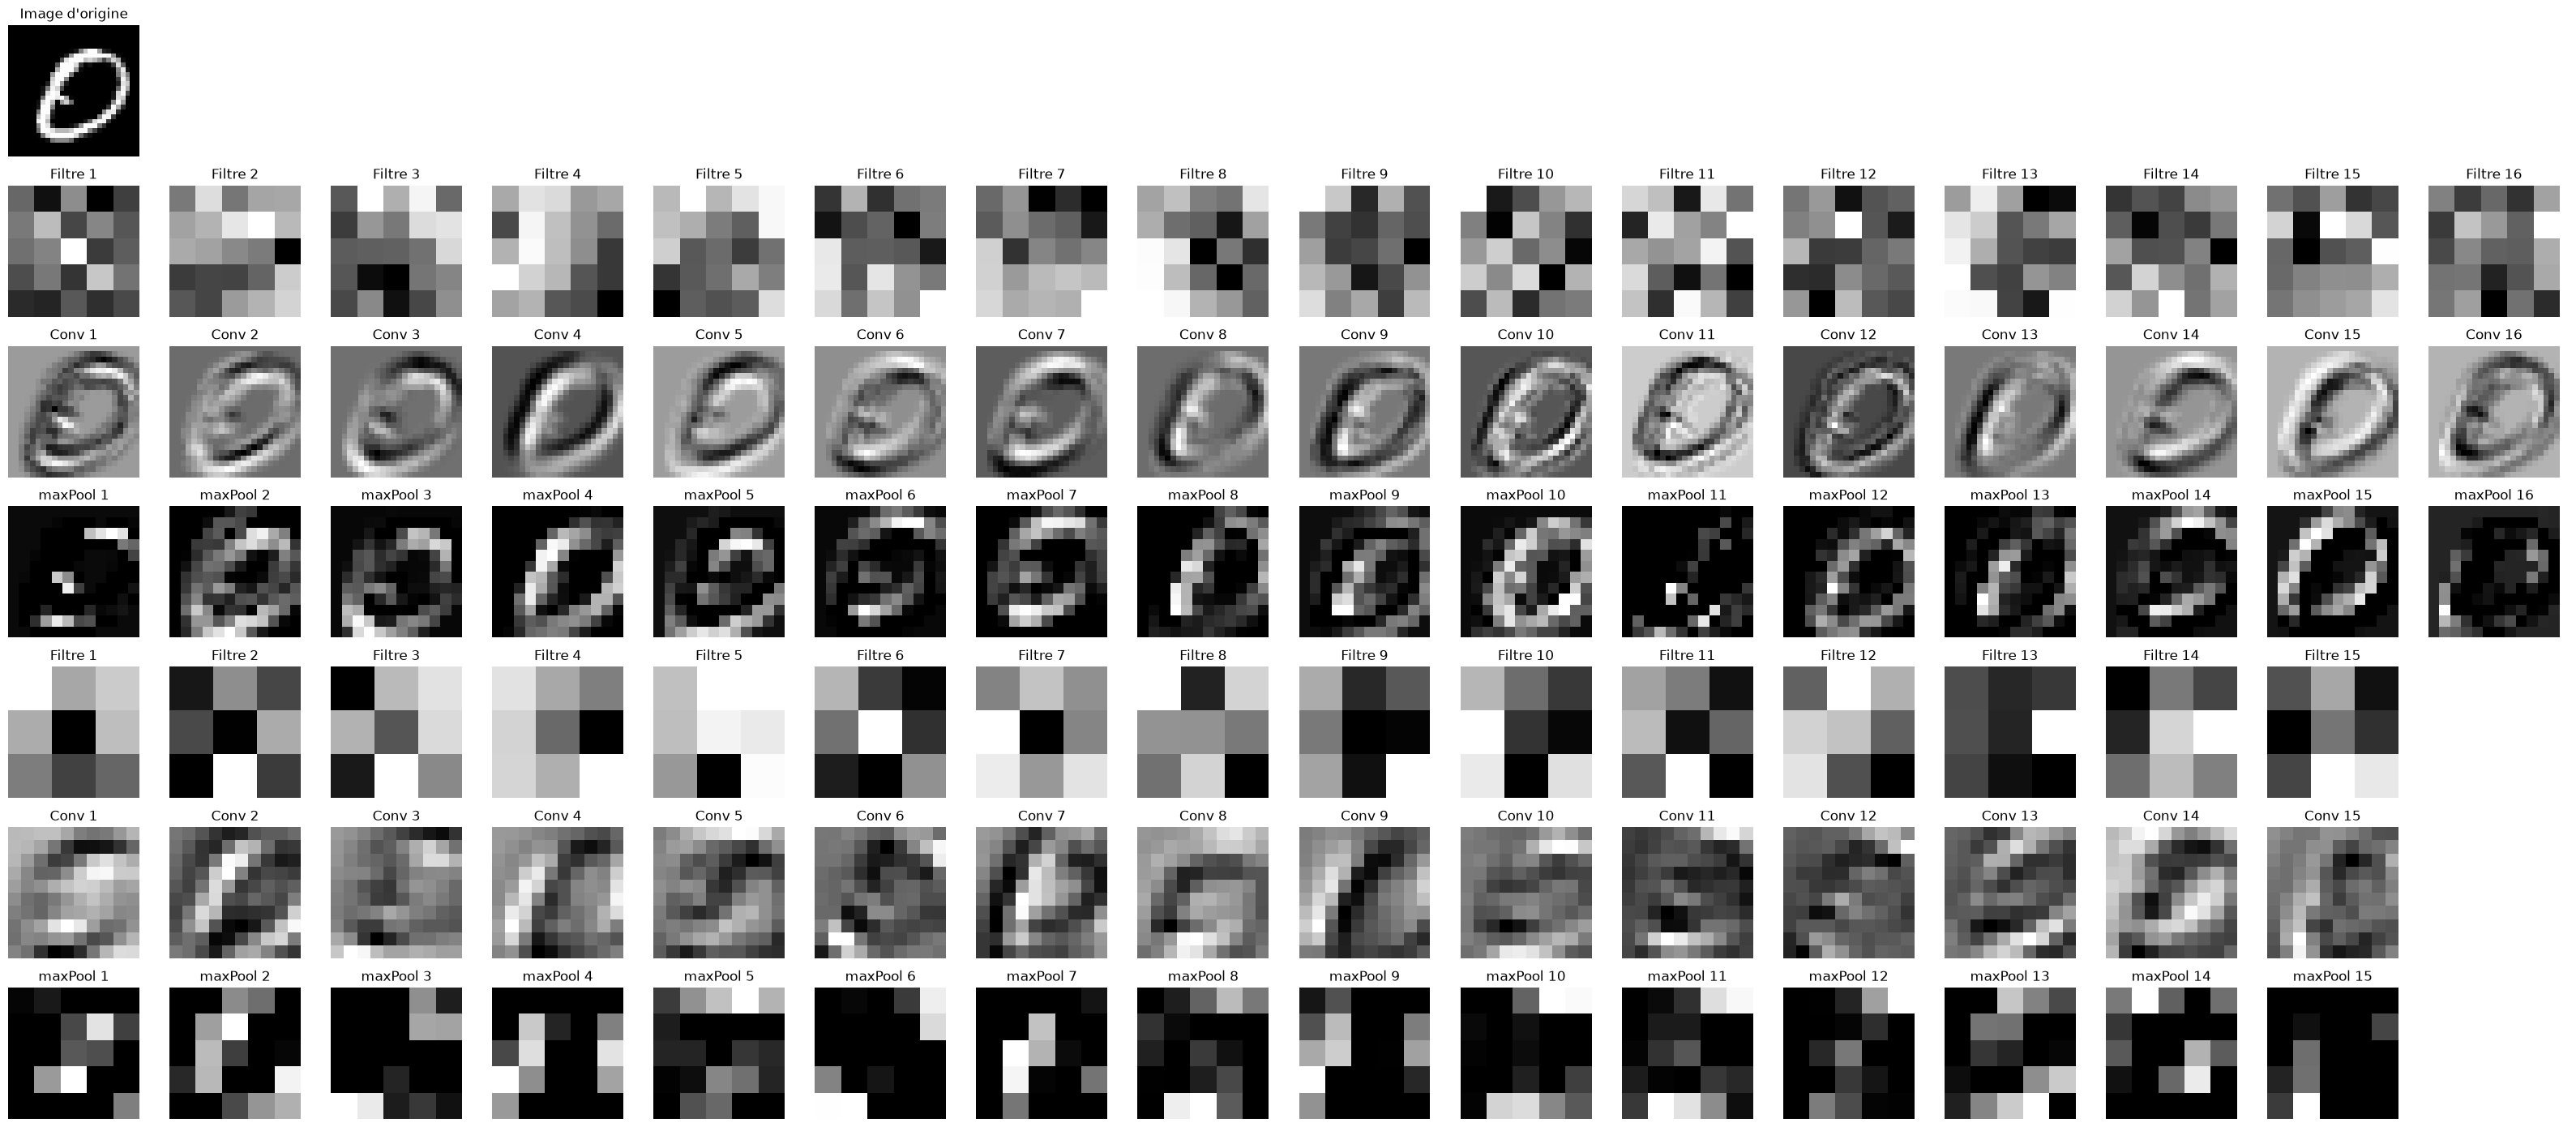

In [253]:
def analyse_conv(model, img, nb_filtre_max=16):
    model.eval()            # passer en mode evaluation (normalement on y est deja)
    x = img.unsqueeze(0)
    lignes = []             # (nom, liste d'images à afficher : filtre/sortie)

    with torch.no_grad():
        for couche in model.features:   # uniquement les couches qui nous interesse
            x = couche.forward(x)
            sortie = x.squeeze(0)
            nb = min(nb_filtre_max, sortie.shape[0])    # on represente maximum `nb_filtre_max` sinon ca peut etre trop petit a l'ecran

            if isinstance(couche, Conv):
                noyau = couche.noyau.detach()
                lignes.append(("Filtre", [noyau[j, 0] for j in range(nb)]))
                lignes.append(("Conv", [sortie[j] for j in range(nb)]))

            elif isinstance(couche, Pool):
                lignes.append((couche.type + "Pool", [sortie[j] for j in range(nb)]))

    if not lignes:
        raise ValueError("Aucune couche Conv/Pool exploitable dans le modèle")

    nb_col = max(len(images) for _, images in lignes)
    nb_lignes = 1 + len(lignes) # +1 pour l'image en entete

    fig, axs = plt.subplots(nb_lignes, nb_col, figsize=(2*nb_col, 2*nb_lignes), squeeze=False)
    for ax in axs.flat:
        ax.axis("off")

    axs[0, 0].imshow(img.squeeze().cpu(), cmap="gray")
    axs[0, 0].set_title("Image d'origine")

    for i, (nom, images) in enumerate(lignes, start=1):
        for j, im in enumerate(images):
            axs[i, j].imshow(im.cpu(), cmap="gray")
            axs[i, j].set_title(f"{nom} {j + 1}")

    fig.tight_layout()
    plt.show()

analyse_conv(models["ml"], X_train[0])

### Carte de Saillance (Saliency Map)
Mesure a quel point chaque pixel de l'image influence le score de la classe prédite.  
Pour avoir la saliency map, on calcule le gradient du score de la classe p/r aux pixels de l'entrée. Un gradient élevé en valeur abs veut dire qu'un petit chg de la valeur du pixel conduit a un chg de classe prédite.

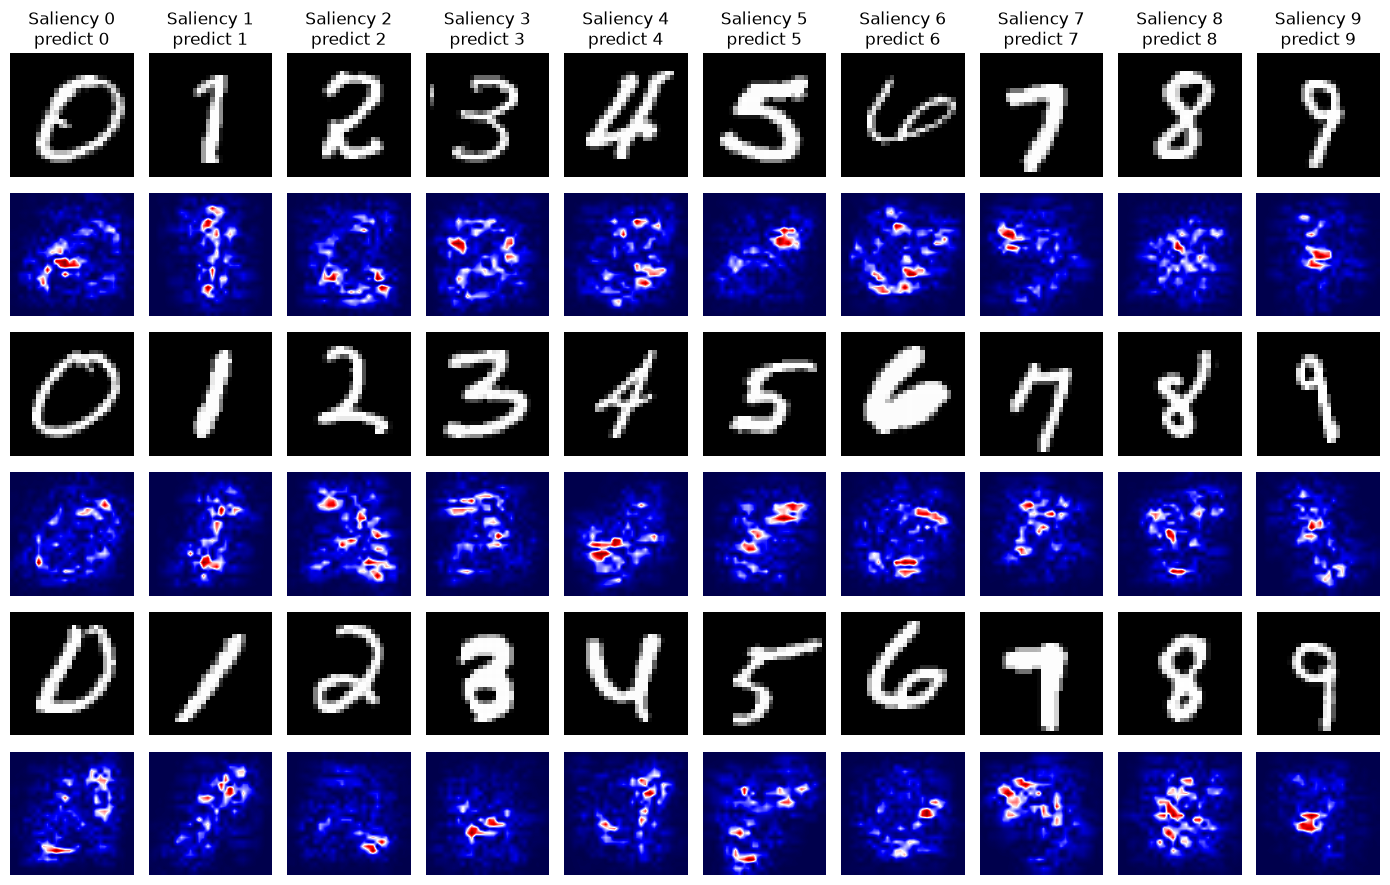

In [263]:
# Saliency (ligne 1-3) et CAM (lignes 4-6) : 3 exemples par chiffre, 1 colonne par chiffre
def carte_saliency(model, img, label):
    model.eval()
    x = img.clone().unsqueeze(0).requires_grad_()       # (1, 1, 28, 28)
    score = model.forward(x)[0, label]
    score.backward()
    return x.grad.abs().squeeze().cpu()


fig, axes = plt.subplots(6, 10, figsize=(14, 9))

for classe in range(10):
    exemples = X_train[y_train == classe][:3]
    for i in range(3):
        img = exemples[i]
        axes[2*i+1, classe].imshow(carte_saliency(models["ml"], img, classe), cmap="seismic", interpolation="bilinear")
        axes[2*i, classe].imshow(img.squeeze(0).cpu(), cmap="gray")

        yhat = models["ml"].predict(img.unsqueeze(0)).item()
        axes[0, classe].set_title(f"Saliency {classe}\npredict {yhat}")
        
for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Class Activation Maps (CAM)
Visualiser les régions qui ont le plus fait réagir les différents filtres. Elle part du principe que la sortie de la dernière couche de convolution indique spatialement quelles sont les régions de l'image qui ont fait réagir le filtre.  
**Précaution :**  
Il serait difficile d'analyser le resultat avec un réseau non-linéaire entre la conv et la sortie. Cependant un réseau plus simple, uniquement linéaire par exemple, permettrait de donner une indication à l'importance de chaque filtre (avec svt une plus grosse erreur en classif en contre partie). Cette technique necessite donc la modification des dernieres couches du réseau de la manière suivante :  
- un pooling de moyennage globale (average pooling de la taille de l'image) est appliqué à chaque filtre de convolution de la dernière couche convolutionnelle : seul le signal moyen de chaque filtre est retenu, sans plus aucune information spatiale.
- un réseau linéaire est ensuite utilisé du nombre de filtre vers nbr de classe, qui va permettre de mettre en évidence l'interet de chaque filtre dans la classif.  

Le réseau ainsi modifié est fine-tuné sur le corpus. L'activation Map est obtennu en sommant les sorties de la dernièe couche convolutionnelle pondérées par les poids du réseau linéaire.  

In [255]:
# Re-entrainer le modele en changeant le classifier pour un linéaire (avec GAP) 
model_CAM = copy.deepcopy(models["ml"])
for p in model_CAM.parameters():
    p.requires_grad = False
model_CAM.classifier = [Pool(kernel=5, type='mean'), Flatten(), Dense(n_out=10)]    # Pour rentrer dans le dense, faire attention que les sortie du pool soit shape[1]
model_CAM.couches = np.concatenate((model_CAM.features, model_CAM.classifier))      # De plus le "5" n'est pas automatique, doit être la taille de la sortie de la derniere conv
print("CAM :", model_CAM.classifier, 
      '\n', 
      "initial :", models["ml"].classifier)  

model_CAM.fit(X_train, y_train, X_val, y_val)
model_CAM.evaluate(X_test, y_test)  # on a bien une loss élevée et F1 assez faible, mais c'est prévu avec la nouvelle tête

CAM : [<__main__.Pool object at 0x00000282DB30E5A0>, <__main__.Flatten object at 0x0000028605E24D40>, <__main__.Dense object at 0x0000028604B35280>] 
 initial : [<__main__.Flatten object at 0x0000028602F3D7C0>, <__main__.Dense object at 0x0000028602F3E240>, <__main__.ReLu object at 0x0000028602F3C4D0>, <__main__.Dense object at 0x0000028602F3CD40>, <__main__.ReLu object at 0x0000028602F3EFF0>, <__main__.Dense object at 0x0000028602F3EED0>]


Epochs:   0%|          | 0/50 [00:00<?, ?it/s]

Batchs:   0%|          | 0/98 [00:00<?, ?it/s]

Batchs:   0%|          | 0/98 [00:00<?, ?it/s]

Batchs:   0%|          | 0/98 [00:00<?, ?it/s]

Batchs:   0%|          | 0/98 [00:00<?, ?it/s]

... (44 outputs left out)

Batchs:   0%|          | 0/98 [00:00<?, ?it/s]

Batchs:   0%|          | 0/98 [00:00<?, ?it/s]

Stop apres 50 epochs : val_loss=0.8782


(0.8707431455339705, 0.7684285714285715)

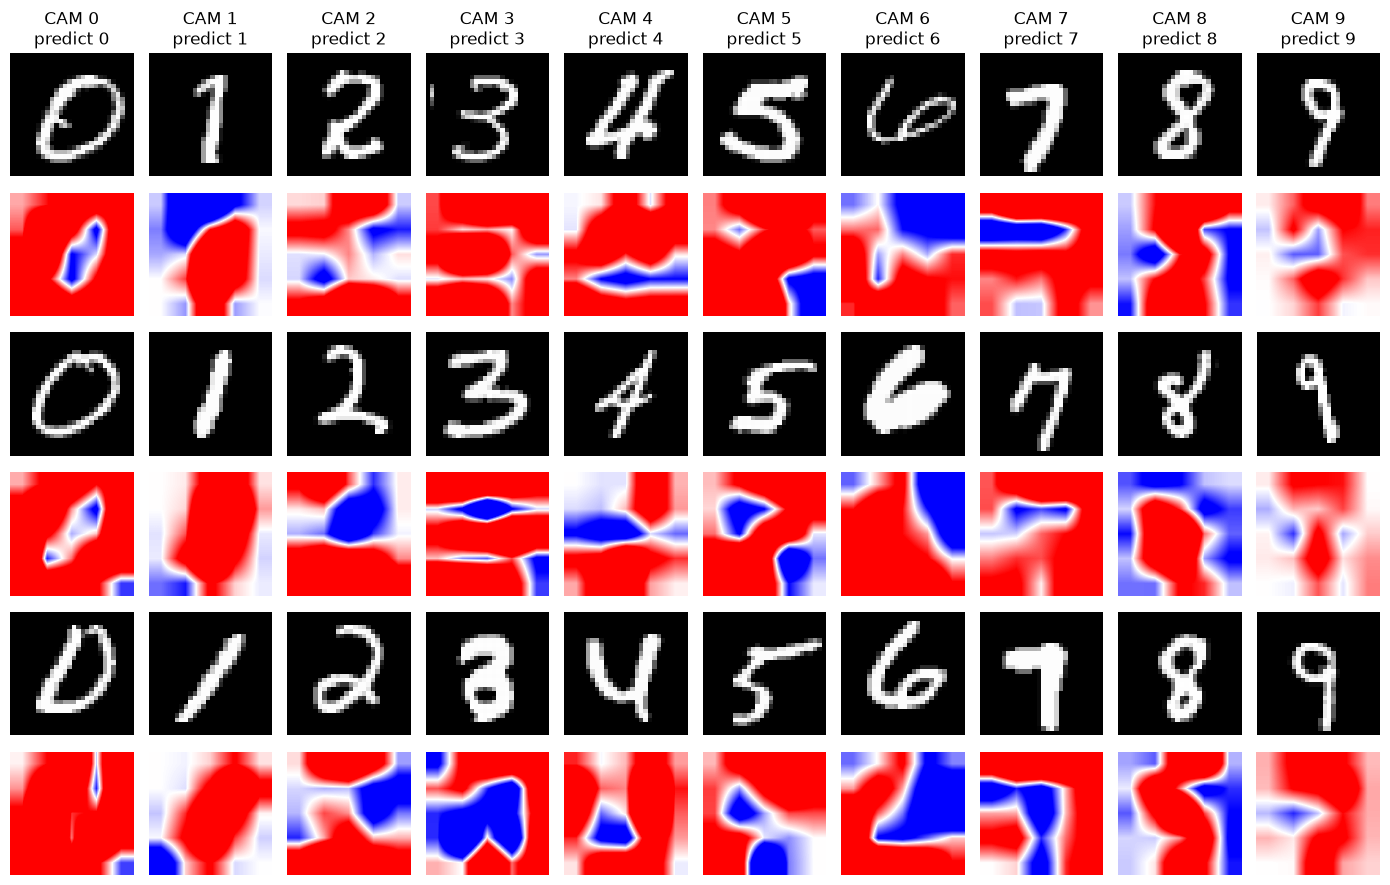

In [264]:
def carte_cam(model, img, label):  # Verifier la taille du kernel du Pool, doit être la taille de la sortie de la derniere conv
    model.eval() # pour se mettre en prediction et pas eval | ici ca sert à désactiver le dropout par ex
    with torch.no_grad():
        x = img.clone().unsqueeze(0)
        for c in model.features:
            x = c.forward(x)
        w = model.classifier[-1].W[:, label]
        return torch.einsum('nfhw,f->hw', x, w).cpu()

fig, axes = plt.subplots(6, 10, figsize=(14, 9))

for classe in range(10):
    exemples = X_train[y_train == classe][:3]
    for i in range(3):
        img = exemples[i]
        axes[2*i + 1, classe].imshow(carte_cam(model_CAM, img, classe), cmap="bwr", vmin=-4, vmax=4, interpolation="bilinear")
        axes[2*i, classe].imshow(img.squeeze(0).cpu(), cmap="gray")
        if i == 0:
            yhat = model_CAM.predict(img.unsqueeze(0)).item()
            axes[0, classe].set_title(f"CAM {classe}\npredict {yhat}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Grad-CAM et Guided Grad-CAM
**Grad-CAM** reprend l'idée du CAM, mais sans modifier l'architecture : il fonctionne avec n'importe quel réseau, y compris avec des couches denses non linéaires après les convolutions (ici le modèle d'origine). Le poids de chaque filtre n'est plus lu dans la couche linéaire, il est calculé par le **gradient** :
- on calcule le gradient du score de la classe par rapport aux cartes de la dernière couche de convolution ;
- le poids de chaque filtre est la **moyenne spatiale** de son gradient (c'est lui qui dit à quel point le filtre influence le score) ;
- la carte est la somme des cartes pondérée par ces poids, suivie d'un **ReLU** : on ne garde que les régions qui *soutiennent* la classe.

La carte garde la taille de la dernière couche de convolution (ici 5×5) : elle est donc grossière, et vide si rien dans l'image ne soutient la classe demandée.

**Guided Grad-CAM** combine la précision de la saliency (fine, de la taille de l'image, mais bruitée) et la localisation du Grad-CAM (nette, mais grossière) :
- le Grad-CAM est agrandi à la taille de l'image (interpolation bilinéaire) et normalisé entre 0 et 1 ;
- il est multiplié terme à terme par la saliency.

On obtient une carte fine, concentrée sur les régions importantes. *Ici, la version utilisée est simplifiée : on multiplie par la saliency (valeur absolue du gradient).* Si le Grad-CAM est nul, le Guided Grad-CAM l'est aussi.


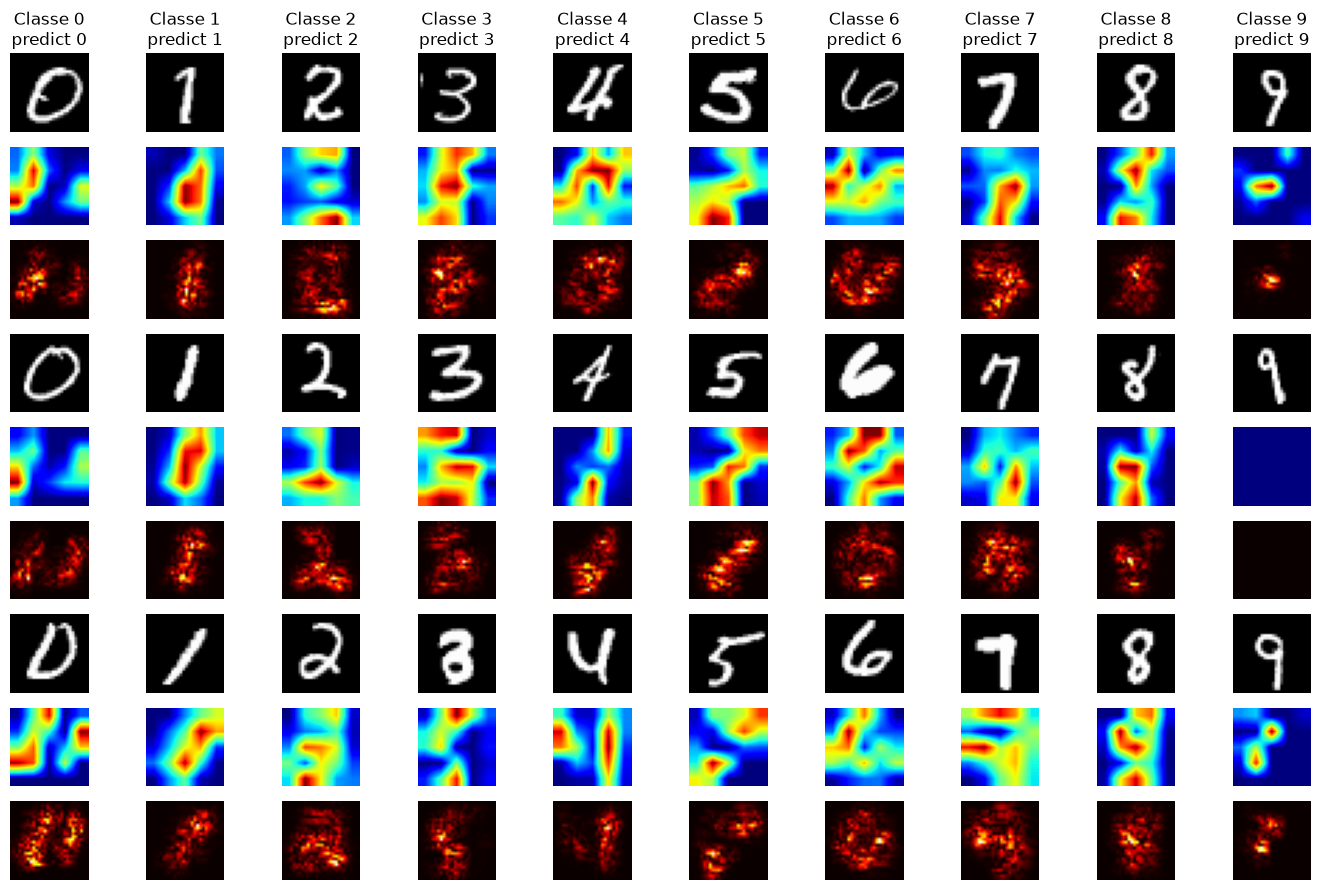

In [259]:
def carte_gradcam(model, img, label):
    model.eval()
    x = img.clone().unsqueeze(0).requires_grad_()       # (1, 1, 28, 28)
    for c in model.features:
        x = c.forward(x)
    a = x                                               # (1, K, H, W) : sortie de la dernière couche de features
    sortie = a
    for c in model.classifier:
        sortie = c.forward(sortie)
    grad = torch.autograd.grad(sortie[0, label], a)[0]  # (1, K, H, W) : d(score) / d(cartes)
    w = grad.mean(dim=(2, 3))                           # (1, K) : poids de chaque filtre = moyenne spatiale du gradient
    return torch.relu(torch.einsum('nf,nfhw->hw', w, a)).detach().cpu()

def carte_guided_gradcam(model, img, label):
    g = carte_gradcam(model, img, label)
    g = torch.nn.functional.interpolate(g[None, None], size=img.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    g = g / (g.max() + 1e-8)                            # normalisé entre 0 et 1
    return g * carte_saliency(model, img, label)

fig, axes = plt.subplots(9, 10, figsize=(14, 9))

for classe in range(10):
    exemples = X_train[y_train == classe][:3]
    for i in range(3):
        img = exemples[i]
        axes[3*i, classe].imshow(img.squeeze(0).cpu(), cmap="gray")
        axes[3*i + 1, classe].imshow(carte_gradcam(models["ml"], img, classe), cmap="jet", interpolation="bilinear")
        axes[3*i + 2, classe].imshow(carte_guided_gradcam(models["ml"], img, classe), cmap="hot", interpolation="bilinear")
        if i == 0:
            yhat = models["ml"].predict(img.unsqueeze(0)).item()
            axes[0, classe].set_title(f"Classe {classe}\npredict {yhat}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Résumé des différentes visualisation de l'apprentissage**

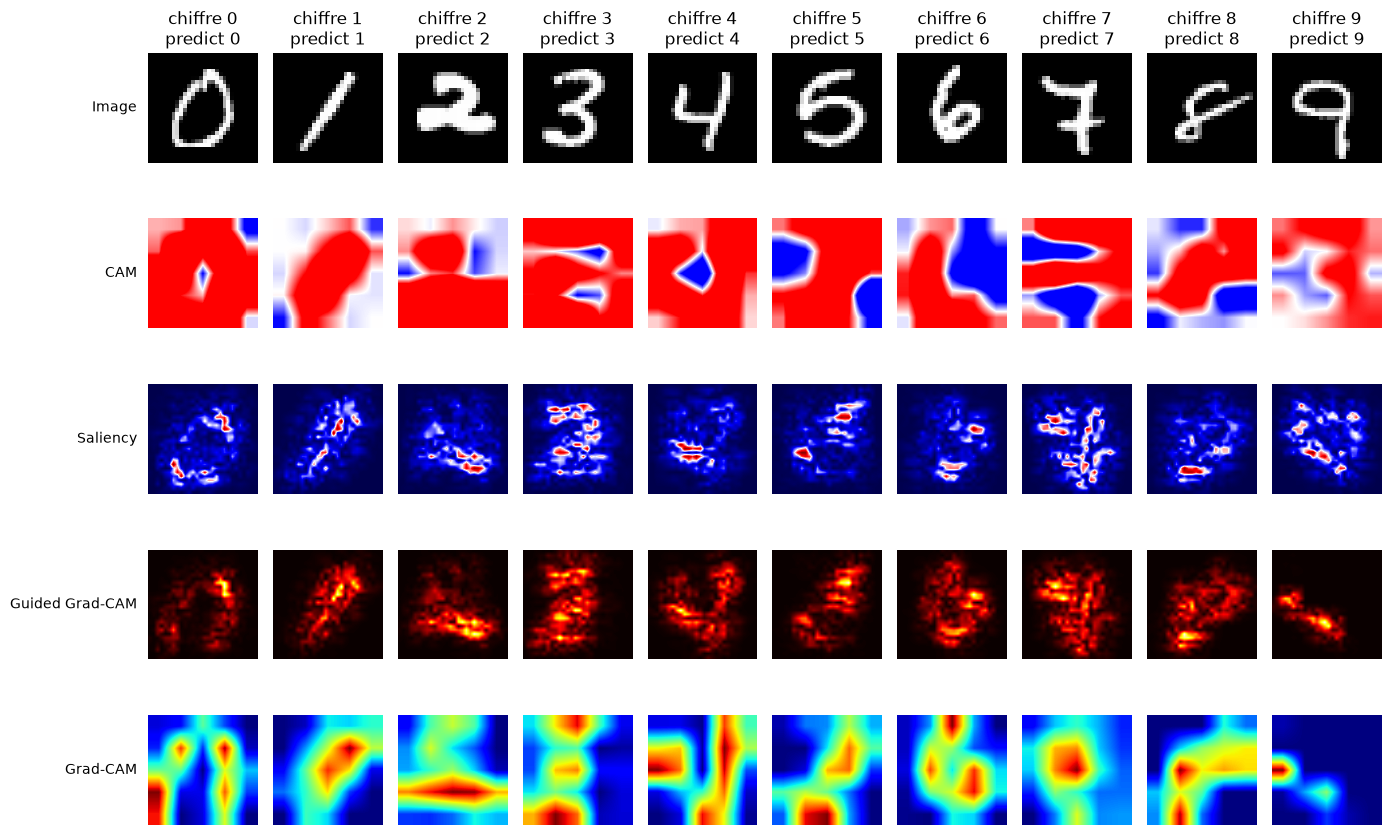

In [ ]:
fig, axes = plt.subplots(5, 10, figsize=(14, 9))
noms_lignes = ["Image", "CAM", "Saliency", "Guided Grad-CAM", "Grad-CAM"]

for classe in range(10):
    exemples = X_train[y_train == classe][6:7]
    img = exemples[0]
    axes[4, classe].imshow(carte_gradcam(models["ml"], img, classe), cmap="jet", interpolation="bilinear")
    axes[3, classe].imshow(carte_guided_gradcam(models["ml"], img, classe), cmap="hot", interpolation="bilinear")
    axes[2, classe].imshow(carte_saliency(models["ml"], img, classe), cmap="seismic", interpolation="bilinear")
    axes[1, classe].imshow(carte_cam(model_CAM, img, classe), cmap="bwr", vmin=-4, vmax=4, interpolation="bilinear")
    axes[0, classe].imshow(img.squeeze(0).cpu(), cmap="gray")

    yhat = models["ml"].predict(img.unsqueeze(0)).item()
    axes[0, classe].set_title(f"chiffre {classe}\npredict {yhat}")

for ax in axes.flat:
    ax.axis("off")

for ligne, nom in enumerate(noms_lignes):
    axes[ligne, 0].text(-0.1, 0.5, nom, transform=axes[ligne, 0].transAxes,
                        ha="right", va="center", fontsize=10)

plt.tight_layout()
plt.show()

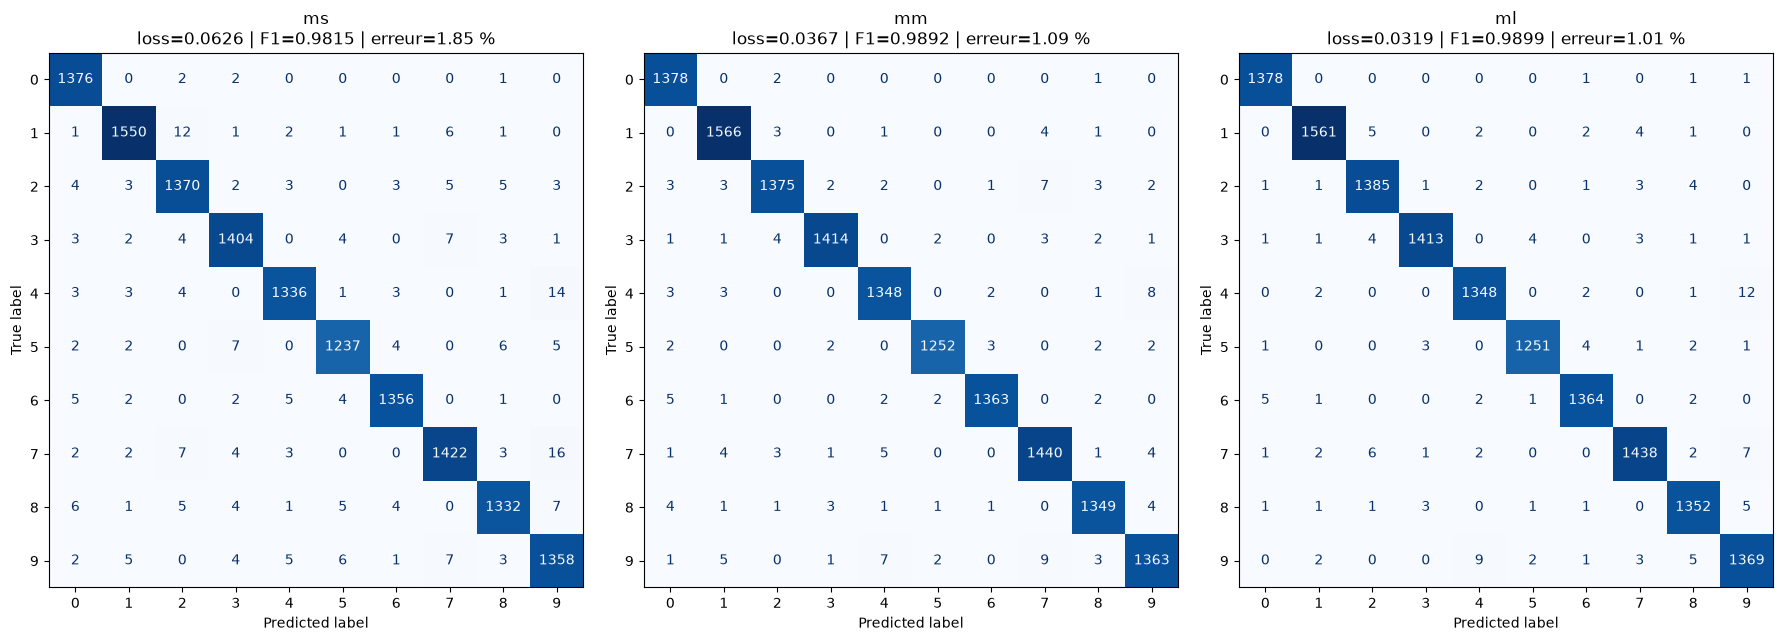

In [278]:
y_true = y_test.cpu().numpy()
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 6), squeeze=False)

for ax, (name, model) in zip(axes[0], models.items()):
    model.eval()
    with torch.no_grad():
        logits = torch.cat([model.forward(X_test[i:i + model.batch_size])
                            for i in range(0, len(X_test), model.batch_size)])
    proba = torch.softmax(logits.double(), dim=1).cpu().numpy()
    pred = proba.argmax(axis=1)

    f1 = f1_score(y_true, pred, average="macro")
    loss_m = model.evaluate(X_test, y_test)[0]
    err = (pred != y_true).mean()

    ConfusionMatrixDisplay(confusion_matrix(y_true, pred)).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{name}\nloss={loss_m:.4f} | F1={f1:.4f} | erreur={err * 100:.2f} %")

plt.tight_layout()
plt.show()